In [37]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns


In [38]:
train = pd.read_csv('data/processed/train_preprocessed.csv')
test = pd.read_csv('data/processed/test_preprocessed.csv')

In [39]:
train.head()

,id,Gender,Age,City,Working Professional or Student,Profession,Academic Pressure,Work Pressure,CGPA,Study Satisfaction,...,overall_satisfaction,stress_satisfaction_gap,sleep_hours_est,work_sleep_ratio,stress_per_hour,is_working_professional,age_x_workload,age_bin,hours_bin,financial_stress_bin
0,0,0,0.695360,0.192690,1,0.048567,-0.446459,1.495218,-0.486345,-0.441965,...,-0.688910,1.444879,1.291755,-1.292218,0.310838,1,-1.142267,3,0,0
1,1,1,-1.161867,0.142206,1,0.055649,-0.446459,0.919263,-0.486345,-0.441965,...,0.022563,0.462412,-1.226638,0.734376,-0.387219,1,-0.374555,1,2,1
2,2,1,-0.596624,0.159196,0,0.534842,3.136517,-1.384554,2.386461,1.071869,...,-0.688910,1.444879,-0.597040,-0.689265,-0.526831,0,-0.853654,1,0,0
3,3,1,-1.484863,0.131293,1,0.055649,-0.446459,1.495218,-0.486345,-0.441965,...,-1.400384,1.936113,-1.226638,1.673979,-0.704518,1,-0.155209,0,3,0
4,4,0,-0.838871,0.125739,1,0.056628,-0.446459,-0.808600,-0.486345,-0.441965,...,-1.400384,-0.028821,-0.597040,0.848267,-0.359297,1,0.133404,1,2,1


# 1. Chiến Lược Feature Selection: Lọc Nhiễu và Khử Đa Cộng Tuyến

## Giai đoạn 1: Lọc Nhiễu bằng Tương quan Mục tiêu (Target Correlation Filter)
- **Cách hoạt động:** Thuật toán tính toán hệ số tương quan Pearson giữa từng đặc trưng (feature) và biến mục tiêu (Depression). Trị tuyệt đối (absolute value) được sử dụng để đánh giá sức mạnh của mối quan hệ, bất kể đó là tương quan thuận (dương) hay tương quan nghịch (âm).

- **Tiêu chí loại bỏ:** Thiết lập một ngưỡng tối thiểu (min_target_corr = 0.02). Bất kỳ biến nào có độ tương quan thấp hơn ngưỡng này sẽ bị coi là nhiễu (noise) và bị loại bỏ.

- **Ý nghĩa:** Trong thực tế, nhiều trường dữ liệu được thu thập không mang lại bất kỳ giá trị dự đoán nào. Việc lọc ngưỡng giúp "thanh lọc" tập dữ liệu ngay từ đầu, giảm thiểu rủi ro mô hình cố gắng tìm kiếm quy luật từ những con số ngẫu nhiên, đồng thời giảm tải khối lượng tính toán cho các bước sau.

## Giai đoạn 2: Lọc Đa Cộng Tuyến Thông Minh (Smart Multicollinearity Filter)
- **Cách hoạt động:** Thuật toán xây dựng một ma trận tương quan giữa các đặc trưng (chỉ tính những biến đã lọt qua Giai đoạn 1) với nhau, không bao gồm biến mục tiêu. Mục đích là tìm ra các cặp biến có độ tương quan nội bộ rất cao (ngưỡng max_feature_corr = 0.85).

- **Điểm sáng của thuật toán (Smart Tie-breaker):** Thay vì xóa ngẫu nhiên một biến trong cặp trùng lặp, thuật toán sẽ so sánh lại sức mạnh dự đoán của chúng ở Giai đoạn 1. Biến nào có độ tương quan với mục tiêu thấp hơn sẽ bị loại bỏ; biến nào mang lại tín hiệu mạnh hơn sẽ được giữ lại.

- **Ý nghĩa:** Hiện tượng đa cộng tuyến (Multicollinearity) xảy ra khi hai biến mang chung một lượng thông tin (ví dụ: overall_pressure và Work Pressure). Việc đưa cả hai vào mô hình không làm tăng độ chính xác mà chỉ gây rối loạn trọng số (weights) và làm sai lệch bảng xếp hạng mức độ quan trọng của đặc trưng (Feature Importance). Cách xử lý "chọn lọc" này đảm bảo chúng ta triệt tiêu được sự trùng lặp mà không vô tình vứt bỏ một đặc trưng quan trọng.

Tổng số features ban đầu: 28

--- BƯỚC 1: LỌC TƯƠNG QUAN VỚI LABEL ---
Giữ lại 26 biến có tương quan >= 0.02
Loại bỏ 2 biến nhiễu: ['Family History of Mental Illness', 'Gender']



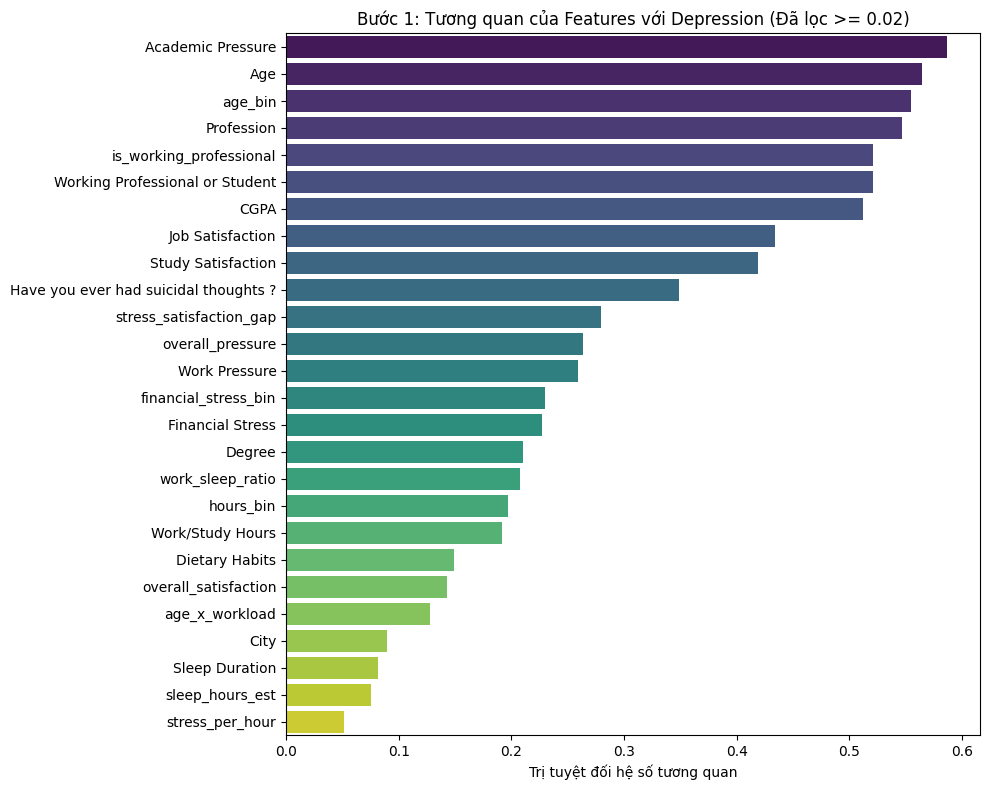

--- BƯỚC 2: LỌC ĐA CỘNG TUYẾN ---
Cặp (age_bin & Age) tương quan 0.98. Xóa 'age_bin' vì dự đoán Target kém hơn.
Cặp (is_working_professional & Academic Pressure) tương quan 0.90. Xóa 'is_working_professional' vì dự đoán Target kém hơn.
Cặp (Working Professional or Student & Academic Pressure) tương quan 0.90. Xóa 'Working Professional or Student' vì dự đoán Target kém hơn.
Cặp (CGPA & Academic Pressure) tương quan 0.88. Xóa 'CGPA' vì dự đoán Target kém hơn.
Cặp (Financial Stress & financial_stress_bin) tương quan 0.95. Xóa 'Financial Stress' vì dự đoán Target kém hơn.
Cặp (hours_bin & work_sleep_ratio) tương quan 0.87. Xóa 'hours_bin' vì dự đoán Target kém hơn.
Cặp (Work/Study Hours & work_sleep_ratio) tương quan 0.90. Xóa 'Work/Study Hours' vì dự đoán Target kém hơn.
Cặp (sleep_hours_est & Sleep Duration) tương quan 0.99. Xóa 'sleep_hours_est' vì dự đoán Target kém hơn.

Loại bỏ 8 biến do đa cộng tuyến: ['age_bin', 'is_working_professional', 'Working Professional or Student', 'CGPA', 

In [40]:

target_col = 'Depression'

# Tách cột 'id' ra khỏi tập dữ liệu để không đưa vào huấn luyện
if 'id' in train.columns:
    train = train.drop(columns=['id'])
    test_ids = test['id']
    test = test.drop(columns=['id'])

print(f"Tổng số features ban đầu: {train.shape[1] - 1}\n")

# ==========================================
# BƯỚC 1: LỌC TƯƠNG QUAN VỚI LABEL (TARGET)
# ==========================================
print("--- BƯỚC 1: LỌC TƯƠNG QUAN VỚI LABEL ---")
min_target_corr = 0.02  # Ngưỡng tối thiểu. Dưới mức này coi như là nhiễu (noise)

# Tính độ tương quan của tất cả features với Depression
target_corr = train.corr()[target_col].drop(target_col)
target_corr_abs = target_corr.abs().sort_values(ascending=False)

# 1.1. Lọc ra các biến đạt tiêu chuẩn
features_step_1 = target_corr_abs[target_corr_abs >= min_target_corr].index.tolist()
dropped_step_1 = target_corr_abs[target_corr_abs < min_target_corr].index.tolist()

print(f"Giữ lại {len(features_step_1)} biến có tương quan >= {min_target_corr}")
print(f"Loại bỏ {len(dropped_step_1)} biến nhiễu: {dropped_step_1}\n")

# 1.2. Vẽ biểu đồ Top Features (Output Hình 1)
plt.figure(figsize=(10, 8))
sns.barplot(
    x=target_corr_abs[features_step_1].values, 
    y=features_step_1, 
    hue=features_step_1, 
    palette='viridis', 
    legend=False
)
plt.title(f'Bước 1: Tương quan của Features với {target_col} (Đã lọc >= {min_target_corr})')
plt.xlabel('Trị tuyệt đối hệ số tương quan')
plt.tight_layout()
plt.show()

# Tạo dataframe mới chỉ chứa các features đã qua Bước 1
train_step_1 = train[features_step_1 + [target_col]]


# ==========================================
# BƯỚC 2: LỌC ĐA CỘNG TUYẾN (MULTICOLLINEARITY)
# ==========================================
print("--- BƯỚC 2: LỌC ĐA CỘNG TUYẾN ---")
max_feature_corr = 0.85  # Ngưỡng đa cộng tuyến. Cặp nào >= mức này sẽ bị xử lý

# Tính ma trận tương quan chỉ giữa các features (không có target)
corr_matrix = train_step_1.drop(columns=[target_col]).corr().abs()

# Lấy nửa trên của ma trận để tránh lặp (A-B và B-A)
upper = corr_matrix.where(np.triu(np.ones(corr_matrix.shape), k=1).astype(bool))

features_to_drop_step_2 = []

# Duyệt qua các cặp có tương quan cao
for column in upper.columns:
    high_corr_vars = upper[column][upper[column] >= max_feature_corr].index.tolist()
    for high_corr_var in high_corr_vars:
        # Nếu cặp này chưa bị loại bỏ ở các vòng lặp trước
        if column not in features_to_drop_step_2 and high_corr_var not in features_to_drop_step_2:
            # Thuật toán thông minh: So sánh độ tương quan với Target
            corr_A_with_target = target_corr_abs[column]
            corr_B_with_target = target_corr_abs[high_corr_var]
            
            # Giữ lại biến tốt hơn, đưa biến kém hơn vào danh sách xóa
            if corr_A_with_target < corr_B_with_target:
                features_to_drop_step_2.append(column)
                print(f"Cặp ({column} & {high_corr_var}) tương quan {upper[column][high_corr_var]:.2f}. Xóa '{column}' vì dự đoán Target kém hơn.")
            else:
                features_to_drop_step_2.append(high_corr_var)
                print(f"Cặp ({column} & {high_corr_var}) tương quan {upper[column][high_corr_var]:.2f}. Xóa '{high_corr_var}' vì dự đoán Target kém hơn.")

# Xóa các biến trùng lặp
final_features = [col for col in features_step_1 if col not in features_to_drop_step_2]

print(f"\nLoại bỏ {len(features_to_drop_step_2)} biến do đa cộng tuyến: {features_to_drop_step_2}")
print(f"Số lượng features CHỐT CUỐI CÙNG: {len(final_features)}\n")



# ==========================================
# 3. LƯU KẾT QUẢ ĐỂ ĐƯA VÀO MODEL
# ==========================================
X_train_final = train[final_features]
y_train_final = train[target_col]
X_test_final = test[final_features]

print("--- HOÀN TẤT ---")
print(f"Kích thước X_train đưa vào mô hình: {X_train_final.shape}")

# 2. Xử lí mất cân bằng nhãn (Label imbalance)

Mặc dù tập dữ liệu có sự chênh lệch giữa hai lớp, nhưng tỉ lệ này (khoảng 4.5:1) chưa đạt mức cực đoan để bắt buộc phải áp dụng các kỹ thuật tái lấy mẫu (resampling). Thay vào đó, chúng ta lựa chọn phương pháp gán trọng số lớp (class weight) để điều chỉnh mức độ ưu tiên cho lớp thiểu số. Đồng thời, thay vì sử dụng Accuracy, các thước đo như F1-score, Precision và Recall sẽ được ưu tiên để đánh giá hiệu năng mô hình một cách khách quan và chính xác hơn trên dữ liệu mất cân bằng.

## 2.1 Loại bỏ Accuracy và Sử dụng Metrics Đặc Thù

## 2.1.1 Cái bẫy của Accuracy (Độ chính xác tổng thể)

Giả sử tập dữ liệu có 95 người khỏe mạnh (0) và 5 người trầm cảm (1). Một mô hình tồi tệ chỉ cần nhắm mắt đoán tất cả là 0 thì Accuracy vẫn đạt mức khổng lồ $95\%$. Tuy nhiên, mô hình này vô giá trị vì nó bỏ sót 100% bệnh nhân trầm cảm. Do đó, tuyệt đối không dùng Accuracy cho dữ liệu mất cân bằng.

## 2.1.2 Các Metrics thay thế (Dựa trên Confusion Matrix)

Chúng ta cần tập trung vào nhóm thiểu số (Nhãn 1 - Positive) thông qua các chỉ số sau:

- Precision (Độ chuẩn xác): Trong tất cả những người mô hình dự đoán là có trầm cảm, bao nhiêu người thực sự bị?$$Precision = \frac{TP}{TP + FP}$$

- Recall (Độ phủ / Độ nhạy): Trong tất cả những người bị trầm cảm thực sự trong dữ liệu, mô hình tìm ra được bao nhiêu người?
$$Recall = \frac{TP}{TP + FN}$$

- F1-Score: Là trung bình điều hòa của Precision và Recall, giúp cân bằng cả 2 yếu tố trên.$$F1 = 2 \times \frac{Precision \times Recall}{Precision + Recall}$$

- ROC-AUC: Đo lường khả năng phân tách giữa 2 lớp của mô hình ở mọi ngưỡng xác suất (thresholds). Điểm AUC là $0.5$ nghĩa là mô hình đoán bừa, điểm $1.0$ là hoàn hảo.

## 2.2 Giải pháp kỹ thuật: Trọng số Lớp (Class Weight)
Nguyên lý đơn giản: Phạt mô hình nặng hơn khi nó đoán sai nhãn thiểu số.

- Nếu đoán sai 1 người khỏe mạnh (Nhãn 0): Mô hình bị trừ 1 điểm.

- Nếu đoán sai 1 người trầm cảm (Nhãn 1): Mô hình bị trừ 5 điểm (hoặc 10 điểm tùy độ chênh lệch).

Nhờ sự "đe dọa" này, mô hình buộc phải chú ý vào việc học các đặc trưng của người trầm cảm.

In [42]:
X_test_final.shape, y_train_final.shape, X_train_final.shape

((93800, 18), (140700,), (140700, 18))

In [49]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import time
from sklearn.model_selection import StratifiedKFold
from sklearn.metrics import roc_auc_score, f1_score, precision_score, recall_score, accuracy_score, roc_curve
from sklearn.base import clone
import warnings
import pprint
warnings.filterwarnings('ignore')

def evaluate_team_models(models_dict, X, y, n_splits=5, random_state=42):
    """
    Hàm chạy Pipeline xài chung cho toàn bộ các model.
    """
    print("=====================================================")
    print(" BẮT ĐẦU PIPELINE ĐÁNH GIÁ")
    print("=====================================================")
    print(f" Shape của dữ liệu huấn luyện: X = {X.shape}, y = {y.shape}")
    print(f" Tỉ lệ nhãn (0/1): {(y==0).sum()} / {(y==1).sum()}")
    print("-----------------------------------------------------\n")
    
    kf = StratifiedKFold(n_splits=n_splits, shuffle=True, random_state=random_state)
    
    # Bảng lưu trữ kết quả tổng hợp
    results_list = []
    
    # Từ điển lưu trữ OOF (Out-of-fold) predictions để xài cho việc vẽ biểu đồ
    oof_predictions = {}
    pp = pprint.PrettyPrinter(indent=4, width=80, compact=True)
    for model_name, model in models_dict.items():
        print(f"⏳ Đang huấn luyện: {model_name}...")
        print("🔧 Cấu hình tham số (Hyperparameters):")
        params = model.get_params()
        pp.pprint(params) # In ra màn hình dưới dạng block dễ nhìn
        print("-----------------------------------------------------")
        start_time = time.time()

        fold_auc, fold_f1, fold_prec, fold_recall, fold_acc = [], [], [], [], []
        oof_probs = np.zeros(len(X))
        
        for fold, (train_idx, val_idx) in enumerate(kf.split(X, y)):
            # Lấy data bằng iloc nếu X, y là DataFrame/Series
            X_tr, y_tr = X.iloc[train_idx], y.iloc[train_idx]
            X_va, y_va = X.iloc[val_idx], y.iloc[val_idx]
            
            # Clone model để đảm bảo công bằng cho mỗi fold
            clf = clone(model)
            clf.fit(X_tr, y_tr)
            
            # Dự đoán
            val_prob = clf.predict_proba(X_va)[:, 1]
            val_pred = clf.predict(X_va)
            oof_probs[val_idx] = val_prob
            
            # Tính metrics
            auc = roc_auc_score(y_va, val_prob)
            f1 = f1_score(y_va, val_pred)
            prec = precision_score(y_va, val_pred)
            rec = recall_score(y_va, val_pred)
            acc = accuracy_score(y_va, val_pred)
            
            fold_auc.append(auc)
            fold_f1.append(f1)
            fold_prec.append(prec)
            fold_recall.append(rec)
            fold_acc.append(acc)
            
            print(f"   - Fold {fold+1}: AUC={auc:.4f} | F1={f1:.4f} | Prec={prec:.4f} | Recall={rec:.4f}")
        
        elapsed_time = time.time() - start_time

        # Tính trung bình và độ lệch chuẩn
        mean_auc, std_auc = np.mean(fold_auc), np.std(fold_auc)
        
        results_list.append({
            'Model': model_name,
            'ROC-AUC (Mean)': f"{mean_auc:.4f} (±{std_auc:.4f})",
            'Accuracy': f"{np.mean(fold_acc):.4f}",
            'F1-Score': np.mean(fold_f1),
            'Precision': np.mean(fold_prec),
            'Recall': np.mean(fold_recall),
            'Time (s)': f"{elapsed_time:.2f}",
            'Raw_AUC_Mean': mean_auc # Dùng để sort bảng
        })
        
        oof_predictions[model_name] = oof_probs
        print(f"✅ Hoàn tất {model_name} -> Mean AUC: {mean_auc:.4f}\n")
        
    # Tạo bảng tổng hợp
    results_df = pd.DataFrame(results_list).sort_values(by='Raw_AUC_Mean', ascending=False)
    results_df = results_df.drop(columns=['Raw_AUC_Mean']).reset_index(drop=True)
    
    print("=====================================================")
    print("🏆 BẢNG TỔNG HỢP METRICS CỦA CÁC MODEL 🏆")
    print("=====================================================")
    display(results_df) # Dùng print(results_df) nếu chạy trên terminal
    
    return results_df, oof_predictions




input 3 model mẫu

In [50]:
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from catboost import CatBoostClassifier

# Bật class_weight cho các model của sklearn
# Với CatBoost, dùng auto_class_weights='Balanced'

models = {
    # Nhóm 1: Logistic Regression với L2 Penalty và C=0.5
    "Logistic Regression (C=0.5)": LogisticRegression(
        penalty='l2',
        C=0.5,
        class_weight='balanced', 
        random_state=42,
        max_iter=1000
    ),
    
    # Nhóm 2: Random Forest với cấu hình cây nông, nhiều cây
    "Random Forest (Tuned)": RandomForestClassifier(
        n_estimators=300,        # 300 cây
        max_depth=8,             # Sâu tối đa 8 tầng
        min_samples_split=5,     # Tối thiểu 5 mẫu để chia nhánh
        class_weight='balanced', 
        random_state=42,
        n_jobs=-1                # Dùng full CPU
    ),
    
    # Nhóm 3: CatBoost với Learning rate chậm, chống overfitting
    "CatBoost (Slow Learn)": CatBoostClassifier(
        iterations=1000,         # 1000 vòng lặp
        learning_rate=0.03,      # Học chậm
        depth=6,                 # Độ sâu trung bình
        l2_leaf_reg=3,           # L2 Regularization
        auto_class_weights='Balanced', 
        verbose=0,               # Tắt log in ra màn hình cho gọn
        random_state=42
    )
}

# Chạy pipeline với từ điển models đã setup ở trên
results_df, oof_preds = evaluate_team_models(models, X_train_final, y_train_final)

 BẮT ĐẦU PIPELINE ĐÁNH GIÁ
 Shape của dữ liệu huấn luyện: X = (140700, 18), y = (140700,)
 Tỉ lệ nhãn (0/1): 115133 / 25567
-----------------------------------------------------

⏳ Đang huấn luyện: Logistic Regression (C=0.5)...
🔧 Cấu hình tham số (Hyperparameters):
{   'C': 0.5,
    'class_weight': 'balanced',
    'dual': False,
    'fit_intercept': True,
    'intercept_scaling': 1,
    'l1_ratio': 0.0,
    'max_iter': 1000,
    'n_jobs': None,
    'penalty': 'l2',
    'random_state': 42,
    'solver': 'lbfgs',
    'tol': 0.0001,
    'verbose': 0,
    'warm_start': False}
-----------------------------------------------------
   - Fold 1: AUC=0.9734 | F1=0.7957 | Prec=0.6954 | Recall=0.9300
   - Fold 2: AUC=0.9722 | F1=0.7918 | Prec=0.6953 | Recall=0.9194
   - Fold 3: AUC=0.9738 | F1=0.7959 | Prec=0.6975 | Recall=0.9265
   - Fold 4: AUC=0.9751 | F1=0.8017 | Prec=0.7039 | Recall=0.9310
   - Fold 5: AUC=0.9734 | F1=0.7981 | Prec=0.7017 | Recall=0.9253
✅ Hoàn tất Logistic Regression (C=0.

,Model,ROC-AUC (Mean),Accuracy,F1-Score,Precision,Recall,Time (s)
0,CatBoost (Slow Learn),0.9751 (±0.0010),0.9187,0.805323,0.712733,0.925568,112.17
1,Logistic Regression (C=0.5),0.9736 (±0.0009),0.9141,0.796638,0.698753,0.926428,3.08
2,Random Forest (Tuned),0.9713 (±0.0013),0.9147,0.796716,0.702455,0.920209,61.36


In [ ]:
# =====================================================
# BƯỚC CUỐI: DỰ ĐOÁN TẬP TEST 
# =====================================================


# 1. Chọn mô hình vô địch từ Bảng xếp hạng (Giả sử là CatBoost)
# Chúng ta khai báo lại y chang cấu hình tốt nhất đó
best_model = CatBoostClassifier(
    iterations=1000,         
    learning_rate=0.03,      
    depth=6,                 
    l2_leaf_reg=3,           
    auto_class_weights='Balanced', 
    verbose=100, # Bật lên 100 để xem tiến trình chạy
    random_state=42
)

print("⏳ Đang huấn luyện Best Model trên 100% tập Train...")
# 2. Huấn luyện trên TOÀN BỘ dữ liệu train (không chia Fold nữa)
best_model.fit(X_train_final, y_train_final)

print("🔍 Đang dự đoán trên tập Test...")
# 3. Tiến hành dự đoán xác suất (Probability) trên tập X_test_final
# Lấy cột index 1 vì chúng ta cần xác suất bị Trầm cảm (Nhãn 1)
test_predictions = best_model.predict_proba(X_test_final)[:, 1]

# # 4. Tạo file nộp bài (Submission)
# # Nhớ lại biến test_ids chúng ta đã tách ra ở khâu Chuẩn bị dữ liệu
# submission = pd.DataFrame({
#     'id': test_ids,
#     'Depression': test_predictions # Có cuộc thi yêu cầu nộp xác suất (float), có cuộc thi yêu cầu nhãn (0/1). Nếu yêu cầu xác suất, nộp biến này.
# })

# # Lưu ra file CSV (Tắt index)
# submission.to_csv('submission_catboost_final.csv', index=False)

# print("✅ Đã xuất file 'submission_catboost_final.csv' thành công!")
# display(submission.head())

⏳ Đang huấn luyện Best Model trên 100% tập Train...
0:	learn: 0.6534092	total: 32.6ms	remaining: 32.6s
100:	learn: 0.2063228	total: 3.03s	remaining: 27s
200:	learn: 0.1977154	total: 5.92s	remaining: 23.5s
300:	learn: 0.1948053	total: 8.48s	remaining: 19.7s
400:	learn: 0.1928329	total: 11.3s	remaining: 16.9s
500:	learn: 0.1906915	total: 14.1s	remaining: 14s
600:	learn: 0.1886339	total: 16.8s	remaining: 11.1s
700:	learn: 0.1866736	total: 19.5s	remaining: 8.33s
800:	learn: 0.1847721	total: 22.1s	remaining: 5.5s
900:	learn: 0.1829867	total: 25.1s	remaining: 2.76s
999:	learn: 0.1813904	total: 28s	remaining: 0us
🔍 Đang dự đoán trên tập Test...
✅ Đã xuất file 'submission_catboost_final.csv' thành công!
Sẵn sàng nộp lên Kaggle!


,id,Depression
0,140700,0.000793
1,140701,0.000727
2,140702,0.065552
3,140703,0.996260
4,140704,0.055507


## LightGBM

In [9]:
import numpy as np
import pandas as pd
from sklearn.model_selection import train_test_split
from lightgbm import LGBMClassifier, early_stopping, log_evaluation
from sklearn.metrics import roc_auc_score

In [10]:
df_proc = pd.read_csv("data/processed/train_preprocessed.csv")
df_raw = pd.read_csv("data/raw/train.csv")

target_col = "Depression"
te_cols = ["City", "Profession"]

if len(df_proc) != len(df_raw):
    raise ValueError("train_preprocessed và train_raw không cùng số dòng, không thể align để encoding an toàn.")

y = df_proc[target_col].copy()

# Loại bỏ các cột đã target-encode trên toàn train để tránh leakage
base_cols = [c for c in df_proc.columns if c not in [target_col] + te_cols]
X_base = df_proc[base_cols].copy()

raw_cat = df_raw[te_cols].fillna("MISSING").astype(str)

idx = np.arange(len(df_proc))
idx_train, idx_valid = train_test_split(
    idx,
    test_size=0.2,
    random_state=42,
    stratify=y
 )

X_train = X_base.iloc[idx_train].copy().reset_index(drop=True)
X_valid = X_base.iloc[idx_valid].copy().reset_index(drop=True)
y_train = y.iloc[idx_train].reset_index(drop=True)
y_valid = y.iloc[idx_valid].reset_index(drop=True)

cat_train = raw_cat.iloc[idx_train].reset_index(drop=True)
cat_valid = raw_cat.iloc[idx_valid].reset_index(drop=True)

global_mean = y_train.mean()

for col in te_cols:
    tmp = pd.DataFrame({col: cat_train[col], target_col: y_train})
    te_map = tmp.groupby(col)[target_col].mean()
    X_train[f"{col}_te"] = cat_train[col].map(te_map).fillna(global_mean).astype(float)
    X_valid[f"{col}_te"] = cat_valid[col].map(te_map).fillna(global_mean).astype(float)

# Tránh warning whitespace của LightGBM
X_train.columns = [c.replace(" ", "_") for c in X_train.columns]
X_valid.columns = [c.replace(" ", "_") for c in X_valid.columns]

print("Train:", X_train.shape, "Valid:", X_valid.shape)
print("Positive rate train:", y_train.mean().round(4))
print("Positive rate valid:", y_valid.mean().round(4))
print("Leakage-safe TE columns added:", ["City_te", "Profession_te"])

Train: (112560, 28) Valid: (28140, 28)
Positive rate train: 0.1817
Positive rate valid: 0.1817
Leakage-safe TE columns added: ['City_te', 'Profession_te']


In [12]:
model = LGBMClassifier(
    objective="binary",
    n_estimators=4000,
    learning_rate=0.03,
    num_leaves=31,
    min_child_samples=60,
    subsample=0.8,
    colsample_bytree=0.8,
    random_state=42
)

model.fit(
    X_train, y_train,
    eval_set=[(X_valid, y_valid)],
    eval_metric="auc",
    callbacks=[
        early_stopping(stopping_rounds=200, verbose=False),
        log_evaluation(period=200)
    ]
)

valid_proba = model.predict_proba(X_valid)[:, 1]
auc = roc_auc_score(y_valid, valid_proba)
print("Validation ROC-AUC:", round(auc, 5))
print("Best iteration:", model.best_iteration_)

[LightGBM] [Info] Number of positive: 20454, number of negative: 92106
[LightGBM] [Info] Auto-choosing row-wise multi-threading, the overhead of testing was 0.003036 seconds.
You can set `force_row_wise=true` to remove the overhead.
And if memory is not enough, you can set `force_col_wise=true`.
[LightGBM] [Info] Total Bins 815
[LightGBM] [Info] Number of data points in the train set: 112560, number of used features: 28
[LightGBM] [Info] [binary:BoostFromScore]: pavg=0.181716 -> initscore=-1.504762
[LightGBM] [Info] Start training from score -1.504762
[200]	valid_0's auc: 0.974314	valid_0's binary_logloss: 0.153151
[400]	valid_0's auc: 0.974463	valid_0's binary_logloss: 0.152167
Validation ROC-AUC: 0.97454
Best iteration: 327


In [13]:
# Inference on full training data and export submission file
test_proc = pd.read_csv("data/processed/test_preprocessed.csv")
test_raw = pd.read_csv("data/raw/test.csv")

# Build full-training features with leakage-safe target encoding for test mapping
X_full = X_base.copy()
y_full = y.copy()
X_test = test_proc[base_cols].copy()

full_cat = df_raw[te_cols].fillna("MISSING").astype(str)
test_cat = test_raw[te_cols].fillna("MISSING").astype(str)
global_mean_full = y_full.mean()

for col in te_cols:
    te_map_full = pd.DataFrame({col: full_cat[col], target_col: y_full}).groupby(col)[target_col].mean()
    X_full[f"{col}_te"] = full_cat[col].map(te_map_full).fillna(global_mean_full).astype(float)
    X_test[f"{col}_te"] = test_cat[col].map(te_map_full).fillna(global_mean_full).astype(float)

X_full.columns = [c.replace(" ", "_") for c in X_full.columns]
X_test.columns = [c.replace(" ", "_") for c in X_test.columns]

best_n_estimators = int(model.best_iteration_) if model.best_iteration_ is not None else 400
final_model = LGBMClassifier(
    objective="binary",
    n_estimators=best_n_estimators,
    learning_rate=0.03,
    num_leaves=31,
    min_child_samples=60,
    subsample=0.8,
    colsample_bytree=0.8,
    random_state=42
)

final_model.fit(X_full, y_full)
test_proba = final_model.predict_proba(X_test)[:, 1]

test_ids = test_proc["id"] if "id" in test_proc.columns else pd.Series(np.arange(len(test_proc)), name="id")
submission = pd.DataFrame({"id": test_ids, "Depression": test_proba})
submission_path = "submission_lightgbm_baseline.csv"
submission.to_csv(submission_path, index=False)

print(f"Saved submission: {submission_path}")
print(submission.head())
print("Rows:", len(submission))

[LightGBM] [Info] Number of positive: 25567, number of negative: 115133
[LightGBM] [Info] Auto-choosing row-wise multi-threading, the overhead of testing was 0.008697 seconds.
You can set `force_row_wise=true` to remove the overhead.
And if memory is not enough, you can set `force_col_wise=true`.
[LightGBM] [Info] Total Bins 815
[LightGBM] [Info] Number of data points in the train set: 140700, number of used features: 28
[LightGBM] [Info] [binary:BoostFromScore]: pavg=0.181713 -> initscore=-1.504786
[LightGBM] [Info] Start training from score -1.504786
Saved submission: submission_lightgbm_baseline.csv
       id  Depression
0  140700    0.001353
1  140701    0.000401
2  140702    0.009175
3  140703    0.977517
4  140704    0.014790
Rows: 93800
